# Group XX - Machine Learning, Element 1: Apply dataset preparation mechanisms
| Item | Details |
|---|---|
| Group | **Group XX** |
| Members | **IGIHOZO Bienvenue** and **MUGISHA Aime Patrick** |
| Question | **Q2 - Next-day rain early warning for MINEMA district disaster offices (own scenario)** |
| Stage | **5 - Engineer and select features (+ Stage 6 final files)** |
| Driver / Navigator | Driver: MUGISHA Aime Patrick / Navigator: IGIHOZO Bienvenue |


## Stage 5 - Engineer and select features (PC 1.4)
All new features use **today and earlier days of the same station only** - never tomorrow - so they are safe.
Selection statistics are computed on the **training years only**.

In [1]:
import sys  # lets us tell Python where our own code (src/) is
from pathlib import Path  # file paths that work on every computer
import warnings  # hide harmless library notices
warnings.filterwarnings("ignore")  # keep output readable
import numpy as np  # maths on whole columns
import pandas as pd  # DataFrame tables
ROOT = Path.cwd().parent  # notebooks/ is inside q2_own_scenario
sys.path.insert(0, str(ROOT / "src"))  # make src/rain_pipeline.py importable
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)  # show all columns
RAW_DIR = ROOT / "data" / "raw" / "gsod"  # original NOAA files (never edited)
import rain_pipeline as rp  # our reusable functions

import matplotlib.pyplot as plt  # charts
import seaborn as sns  # charts
INTERIM, PROCESSED, FIG = ROOT / "data" / "interim", ROOT / "data" / "processed", ROOT / "docs" / "figures"  # folders
PROCESSED.mkdir(parents=True, exist_ok=True)  # create if needed
clean = pd.read_csv(INTERIM / "rain_clean.csv", parse_dates=["DATE"])  # clean data
feat = rp.add_features(clean)  # features computed on the full timeline (lags need the previous day)
train, val, test = rp.chronological_split(feat)  # same time split as Stage 4
print({n: p.shape for n, p in [("train", train), ("val", val), ("test", test)]})  # sizes

{'train': (8438, 33), 'val': (641, 33), 'test': (739, 33)}


Lags (yesterday, last 3 days) are computed **before** splitting because the first day of 2023 legitimately knows the weather
of 31 Dec 2022 - that is the past, not the future, so there is no leakage.

In [2]:
new_cols = ["month", "rw_season", "doy_sin", "doy_cos", "dewpoint_spread_c", "rel_humidity_pct", "diurnal_range_c",
            "rain_yesterday", "temp_change_c", "rain_days_last3", "log_prcp_mm"]  # 11 new features
train[["station", "DATE", "rain"] + new_cols + [rp.TARGET]].head(8)  # first rows with the new columns

,station,DATE,rain,month,rw_season,doy_sin,doy_cos,dewpoint_spread_c,rel_humidity_pct,diurnal_range_c,rain_yesterday,temp_change_c,rain_days_last3,log_prcp_mm,rain_tomorrow
0,Gisenyi,2016-02-26,0,2,Short dry,0.830797,0.556576,5.38,71.623517,11.39,NaN,NaN,NaN,1.398717,1
1,Gisenyi,2016-02-27,1,2,Short dry,0.840248,0.542202,3.61,79.921242,11.22,0.0,-1.00,NaN,0.000000,0
2,Gisenyi,2016-02-28,0,2,Short dry,0.849450,0.527668,5.83,69.694392,13.22,1.0,1.45,1.0,3.214064,0
3,Gisenyi,2016-02-29,0,2,Short dry,0.858402,0.512978,6.95,65.198770,10.22,0.0,1.39,1.0,0.000000,0
4,Gisenyi,2016-03-01,0,3,Long rains,0.867099,0.498137,7.44,63.218363,11.22,0.0,0.05,0.0,0.000000,0
5,Gisenyi,2016-03-02,0,3,Long rains,0.875539,0.483147,7.00,65.109598,6.00,0.0,0.50,0.0,0.000000,1
6,Gisenyi,2016-03-03,1,3,Long rains,0.883720,0.468015,4.39,76.221502,6.00,0.0,-2.50,1.0,NaN,0
7,Gisenyi,2016-03-06,0,3,Long rains,0.906686,0.421806,7.00,65.168722,13.50,NaN,NaN,NaN,0.000000,0


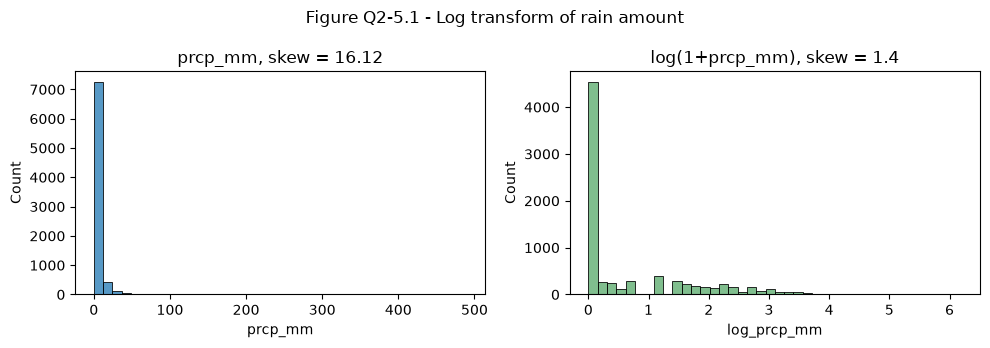

In [3]:
sk = train[["prcp_mm", "log_prcp_mm", "wind_kmh", "rel_humidity_pct"]].skew().round(2)  # skewness
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))  # two histograms
sns.histplot(train["prcp_mm"], bins=40, ax=axes[0]); axes[0].set_title(f"prcp_mm, skew = {sk['prcp_mm']}")  # before
sns.histplot(train["log_prcp_mm"], bins=40, ax=axes[1], color="#55A868"); axes[1].set_title(f"log(1+prcp_mm), skew = {sk['log_prcp_mm']}")  # after
fig.suptitle("Figure Q2-5.1 - Log transform of rain amount"); plt.tight_layout()  # title
plt.savefig(FIG / "q2_fig5_1_log_prcp.png", dpi=120); plt.show()  # save and display

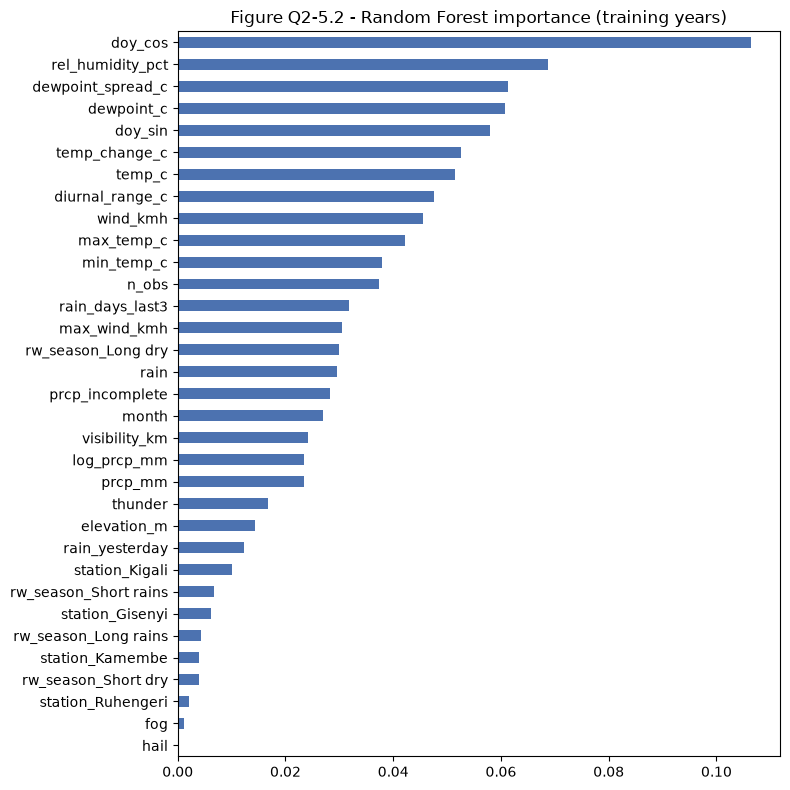

,corr_with_target,mutual_info,rf_importance
doy_cos,0.232,0.083,0.106
rel_humidity_pct,0.271,0.038,0.069
dewpoint_spread_c,-0.269,0.029,0.061
dewpoint_c,0.227,0.028,0.061
doy_sin,0.037,0.075,0.058
temp_change_c,-0.022,0.000,0.053
temp_c,-0.152,0.008,0.051
diurnal_range_c,-0.061,0.010,0.048
wind_kmh,-0.029,0.006,0.045
max_temp_c,-0.009,0.002,0.042


In [4]:
from sklearn.feature_selection import mutual_info_classif  # dependence measure for a 0/1 target
from sklearn.ensemble import RandomForestClassifier  # quick model for importance
cands = ["temp_c", "dewpoint_c", "max_temp_c", "min_temp_c", "wind_kmh", "max_wind_kmh", "visibility_km", "prcp_mm",
         "elevation_m", "fog", "rain", "hail", "thunder", "prcp_incomplete", "n_obs", "month", "doy_sin", "doy_cos",
         "dewpoint_spread_c", "rel_humidity_pct", "diurnal_range_c", "rain_yesterday", "temp_change_c",
         "rain_days_last3", "log_prcp_mm"]  # numeric candidates
X = train[cands].fillna(train[cands].median())  # simple fill (train medians) only for measuring
X = X.join(pd.get_dummies(train[["station", "rw_season"]], dtype=float))  # categories as 0/1
y = train[rp.TARGET]  # target
corr = train[cands + [rp.TARGET]].corr()  # correlations (train)
mi = pd.Series(mutual_info_classif(X, y, random_state=rp.SEED), index=X.columns)  # mutual information
rf = RandomForestClassifier(n_estimators=300, random_state=rp.SEED, n_jobs=-1, min_samples_leaf=5).fit(X, y)  # forest
rank = pd.DataFrame({"corr_with_target": corr[rp.TARGET].reindex(X.columns), "mutual_info": mi,
                     "rf_importance": rf.feature_importances_}, index=X.columns).sort_values("rf_importance", ascending=False)  # table
fig, ax = plt.subplots(figsize=(8, 8))  # chart
rank["rf_importance"].sort_values().plot.barh(ax=ax, color="#4C72B0")  # bars
ax.set_title("Figure Q2-5.2 - Random Forest importance (training years)"); plt.tight_layout()  # title
plt.savefig(FIG / "q2_fig5_2_rf_importance.png", dpi=120); plt.show()  # save and display
rank.round(3)  # table

In [5]:
from sklearn.feature_selection import VarianceThreshold  # selection method 1
vt = VarianceThreshold(0.01).fit(X)  # near-constant columns
low_var = [c for c, k in zip(X.columns, vt.get_support()) if not k]  # removed by the threshold
print("near-constant:", low_var)  # e.g. hail (almost never)
up = corr.loc[cands, cands].abs().where(np.triu(np.ones((len(cands),) * 2), k=1).astype(bool))  # upper triangle
pairs = up.stack()[lambda s: s > 0.85].round(3)  # strongly related pairs
print("pairs with |r| > 0.85:\n", pairs.to_string())  # list

near-constant: ['hail']
pairs with |r| > 0.85:
 dewpoint_spread_c  rel_humidity_pct    0.994


In [6]:
DROP = {  # removed feature -> reason (evidence above)
    "hail": f"near-constant (variance threshold): hail on {train['hail'].mean():.1%} of days",
    "elevation_m": "one value per station - duplicates the station column",
    "max_temp_c": "strongly correlated with temp_c; its information kept in diurnal_range_c",
    "min_temp_c": "strongly correlated with temp_c/dewpoint_c; its information kept in diurnal_range_c",
    "prcp_mm": "very skewed and often incomplete; replaced by log_prcp_mm + prcp_incomplete",
    "month": "replaced by doy_sin/doy_cos (circular) and rw_season (agronomic seasons)",
    "dewpoint_c": f"r = {corr.loc['dewpoint_c', 'rel_humidity_pct']:.2f} with rel_humidity_pct, which is easier to explain",
    "dewpoint_spread_c": f"r = {corr.loc['dewpoint_spread_c', 'rel_humidity_pct']:.3f} with rel_humidity_pct (same information, |r| > 0.85)",
    "n_obs": f"low importance ({rank.loc['n_obs', 'rf_importance']:.3f}); quality bookkeeping, not weather",
}
FINAL_NUM = ["temp_c", "rel_humidity_pct", "diurnal_range_c", "wind_kmh", "max_wind_kmh",
             "visibility_km", "log_prcp_mm", "temp_change_c", "rain_days_last3", "doy_sin", "doy_cos"]  # scaled numbers
FINAL_FLAG = ["rain", "thunder", "fog", "rain_yesterday", "prcp_incomplete"]  # 0/1 flags
FINAL_CAT = ["station", "rw_season"]  # one-hot categories
print(len(FINAL_NUM + FINAL_FLAG + FINAL_CAT), "selected inputs:", FINAL_NUM + FINAL_FLAG + FINAL_CAT)  # final list

18 selected inputs: ['temp_c', 'rel_humidity_pct', 'diurnal_range_c', 'wind_kmh', 'max_wind_kmh', 'visibility_km', 'log_prcp_mm', 'temp_change_c', 'rain_days_last3', 'doy_sin', 'doy_cos', 'rain', 'thunder', 'fog', 'rain_yesterday', 'prcp_incomplete', 'station', 'rw_season']


In [7]:
from sklearn.compose import ColumnTransformer  # recipe
from sklearn.pipeline import Pipeline  # steps
from sklearn.impute import SimpleImputer  # missing values
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # encoding/scaling
import joblib  # save the fitted recipe
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), FINAL_NUM),
    ("flag", SimpleImputer(strategy="most_frequent"), FINAL_FLAG),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FINAL_CAT),
], verbose_feature_names_out=False)  # readable names
prep.fit(train)  # learn from 2015-2022 only
names = list(prep.get_feature_names_out())  # output column names
for n, part in [("train", train), ("val", val), ("test", test)]:  # each split
    out = pd.concat([part[["station", "DATE"]].reset_index(drop=True).rename(columns={"station": "station_id"}),
                     pd.DataFrame(prep.transform(part), columns=names), part[[rp.TARGET]].reset_index(drop=True)], axis=1)  # ids + X + y
    out.to_csv(PROCESSED / f"rain_{n}.csv", index=False)  # model-ready file
    part.to_csv(PROCESSED / f"rain_{n}_readable.csv", index=False)  # un-scaled copy
    print(f"{n:<5} {out.shape}  missing: {int(out.drop(columns=['station_id', 'DATE']).isna().sum().sum())}")  # check
joblib.dump(prep, PROCESSED / "preprocessor.joblib")  # save the recipe

train (8438, 27)  missing: 0
val   (641, 27)  missing: 0
test  (739, 27)  missing: 0


['D:\\Y4 Btech\\Machine learning\\group-XX-repository\\q2_own_scenario\\data\\processed\\preprocessor.joblib']

In [8]:
fj = pd.DataFrame([  # feature table
    ("rw_season", "month -> Long rains / Short rains / Long dry / Short dry", "rain follows Rwanda's seasons (Fig. Q2-3.4b)", "kept"),
    ("doy_sin, doy_cos", "day of year on a circle", "31 Dec and 1 Jan are neighbours", "kept"),
    ("rel_humidity_pct", "Magnus formula from temp and dew point", f"r = {corr.loc['rel_humidity_pct', rp.TARGET]:.2f} with target", "kept"),
    ("dewpoint_spread_c", "temp_c - dewpoint_c", f"r = {corr.loc['dewpoint_spread_c', rp.TARGET]:.2f}; created, then removed (duplicate of humidity)", "removed"),
    ("diurnal_range_c", "max_temp_c - min_temp_c", f"r = {corr.loc['diurnal_range_c', rp.TARGET]:.2f}; cloudy days vary less", "kept"),
    ("rain_yesterday", "rain flag of the previous day (if consecutive)", f"r = {corr.loc['rain_yesterday', rp.TARGET]:.2f}; wet spells persist", "kept"),
    ("rain_days_last3", "rainy days among the last 3 consecutive days", f"r = {corr.loc['rain_days_last3', rp.TARGET]:.2f}", "kept"),
    ("temp_change_c", "temp today - temp yesterday", f"r = {corr.loc['temp_change_c', rp.TARGET]:.2f}; cooling before rain", "kept"),
    ("log_prcp_mm", "log(1 + prcp_mm)", f"skew {sk['prcp_mm']} -> {sk['log_prcp_mm']}", "kept"),
    ("rain, thunder, fog, prcp_incomplete", "decoded from FRSHTT / PRCP flag", f"rain today r = {corr.loc['rain', rp.TARGET]:.2f}", "kept"),
] + [(k, "-", v, "removed") for k, v in DROP.items()], columns=["feature", "how_created", "evidence", "decision"])
fj.to_csv(ROOT / "docs" / "feature_justification.csv", index=False)  # save
fj  # display

,feature,how_created,evidence,decision
0,rw_season,month -> Long rains / Short rains / Long dry /...,rain follows Rwanda's seasons (Fig. Q2-3.4b),kept
1,"doy_sin, doy_cos",day of year on a circle,31 Dec and 1 Jan are neighbours,kept
2,rel_humidity_pct,Magnus formula from temp and dew point,r = 0.27 with target,kept
3,dewpoint_spread_c,temp_c - dewpoint_c,"r = -0.27; created, then removed (duplicate of...",removed
4,diurnal_range_c,max_temp_c - min_temp_c,r = -0.06; cloudy days vary less,kept
5,rain_yesterday,rain flag of the previous day (if consecutive),r = 0.21; wet spells persist,kept
6,rain_days_last3,rainy days among the last 3 consecutive days,r = 0.31,kept
7,temp_change_c,temp today - temp yesterday,r = -0.02; cooling before rain,kept
8,log_prcp_mm,log(1 + prcp_mm),skew 16.12 -> 1.4,kept
9,"rain, thunder, fog, prcp_incomplete",decoded from FRSHTT / PRCP flag,rain today r = 0.26,kept


In [9]:
final = pd.read_csv(PROCESSED / "rain_train.csv")  # read back
final.info()  # all inputs numeric, no missing values
sorted(p.name for p in PROCESSED.iterdir())  # delivered files

<class 'pandas.DataFrame'>
RangeIndex: 8438 entries, 0 to 8437
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   station_id             8438 non-null   str    
 1   DATE                   8438 non-null   str    
 2   temp_c                 8438 non-null   float64
 3   rel_humidity_pct       8438 non-null   float64
 4   diurnal_range_c        8438 non-null   float64
 5   wind_kmh               8438 non-null   float64
 6   max_wind_kmh           8438 non-null   float64
 7   visibility_km          8438 non-null   float64
 8   log_prcp_mm            8438 non-null   float64
 9   temp_change_c          8438 non-null   float64
 10  rain_days_last3        8438 non-null   float64
 11  doy_sin                8438 non-null   float64
 12  doy_cos                8438 non-null   float64
 13  rain                   8438 non-null   float64
 14  thunder                8438 non-null   float64
 15  fog            

['preprocessor.joblib',
 'rain_test.csv',
 'rain_test_readable.csv',
 'rain_train.csv',
 'rain_train_readable.csv',
 'rain_val.csv',
 'rain_val_readable.csv']